In [36]:
import pandas as pd
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import os

In [37]:
df = pd.read_csv("color_data/tst.csv")
df.shape

(165534, 10)

In [38]:
seq_name = df["seq_name"].unique()[0]
seq_name

'ILoffice_H250_Cam2_MR_VLC_4HO_20fps_r1_20220607_143207.avi.seq'

In [39]:
tmp_df = df[df["seq_name"] == seq_name]
tmp_df.shape

(5233, 10)

In [40]:
avi_path = tmp_df["avi_path"].unique()[0]
avi_name = avi_path.split("/")[-1].replace(".avi", "")
camera_type = tmp_df["camera_type"].unique()[0]
camera_type, avi_name

('SPCA2281B-L0', 'ILoffice_H250_Cam2_MR_VLC_4HO_20fps_r1_20220607_143207')

In [41]:
frames = []
cap = cv2.VideoCapture(avi_path)
while True:
    ret, frame = cap.read()
    if not ret:
        break
    frames.append(frame)

cap.release()

In [42]:
frame_nums = tmp_df["frame_n"].unique()[::10]
frame_nums.shape

(236,)

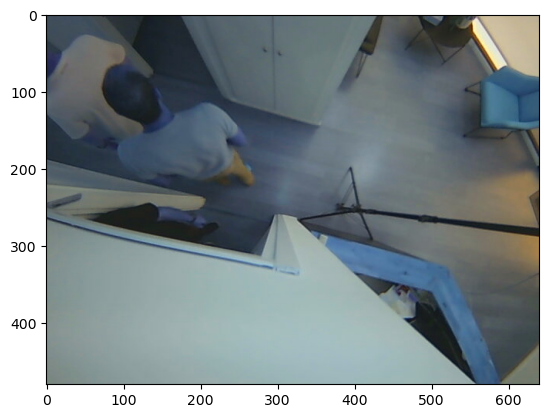

In [43]:
plt.imshow(frames[frame_nums[5]])

In [44]:
images = []
annotations = []

for frame_n in tqdm(frame_nums):
    img_id = f"{avi_name}__{frame_n}.jpg"
    tmp = frames[frame_n].copy()
    h, w, _ = tmp.shape
    
    img_info = {
        "id": None, 
        "width": w, 
        "height": h, 
        "file_name": img_id, 
        "license": None,
        "date_captured": None,
    }

    axis = (1)
    if camera_type in ["SPCA2281B-L0", "SPCA2281B-L1"]:
        axis=(0, 1)

    tmp = np.flip(tmp, axis=axis).astype(np.uint8)

    for _, row in tmp_df[tmp_df["frame_n"] == frame_n].iterrows():
        cv2.rectangle(tmp, (row["x_left"], row["y_top"]), (row["x_left"] + row["width"], row["y_top"] + row["height"]), (255, 0, 0), 2)
        annotation = {
            "id": None, 
            "image_id": None,
            "category_id": 1,
            "segmentation": [], 
            "area": 0, 
            "bbox": [row["x_left"], row["y_top"], row["width"], row["y_top"], row["height"]], 
            "iscrowd": 0,
        }

    cv2.imwrite(os.path.join("color_dataset/images", img_id), tmp)

100%|██████████| 236/236 [00:01<00:00, 170.01it/s]
